# LAB3 - Bài 2

## Câu a

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import metrics

import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense, Dropout

In [2]:
# Cố định seed để kết quả huấn luyện Neural Network có thể lặp lại
keras.utils.set_random_seed(42)

In [3]:
# Đọc bộ dữ liệu train, test của MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

## Câu b

In [4]:
# Kích thước của tập train, test
print("Train images:", train_images.shape, "- Train labels:", train_labels.shape)
print("Test images:", test_images.shape, "- Test labels:", test_labels.shape)

Train images: (60000, 28, 28) - Train labels: (60000,)
Test images: (10000, 28, 28) - Test labels: (10000,)


Đặng Phan Duy - 6451071010

## Câu c

In [5]:
# Chuẩn hóa các giá trị pixel của ảnh về đoạn [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

print("Train - Min:", train_images.min(), "- Max:", train_images.max())
print("Test - Min:", test_images.min(), "- Max:", test_images.max())

Train - Min: 0.0 - Max: 1.0
Test - Min: 0.0 - Max: 1.0


Đặng Phan Duy - 6451071010

## Câu d

In [6]:
# Chia tập train ban đầu thành tập train và tập validation theo tỷ lệ 8:2
train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42)

print("Train images:", train_images.shape, "- Train labels:", train_labels.shape)
print("Validation images:", validation_images.shape, "- Validation labels:", validation_labels.shape)

Train images: (48000, 28, 28) - Train labels: (48000,)
Validation images: (12000, 28, 28) - Validation labels: (12000,)


Đặng Phan Duy - 6451071010

## Câu e

In [7]:
# Xây dựng Neural Network
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                          # làm phẳng ảnh 28x28 thành vector 784 chiều
    Dense(128, activation='relu'),      # 128 neuron, hàm kích hoạt Relu
    Dropout(0.2),                       # mỗi neuron có xác suất 20% bị tắt
    Dense(10, activation='softmax')     # 10 class (chữ số 0 - 9)
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Đặng Phan Duy - 6451071010

## Câu f

In [8]:
# Biên dịch mô hình
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

## Câu g

In [9]:
# Huấn luyện mô hình trên tập train, đánh giá với tập validation
history = model.fit(train_images, train_labels, epochs=5, batch_size=32,
                    validation_data=(validation_images, validation_labels))

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9050 - loss: 0.3287 - val_accuracy: 0.9537 - val_loss: 0.1658
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9531 - loss: 0.1612 - val_accuracy: 0.9638 - val_loss: 0.1221
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9647 - loss: 0.1204 - val_accuracy: 0.9704 - val_loss: 0.1033
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9706 - loss: 0.0969 - val_accuracy: 0.9733 - val_loss: 0.0923
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9745 - loss: 0.0817 - val_accuracy: 0.9732 - val_loss: 0.0899


Đặng Phan Duy - 6451071010

## Câu h

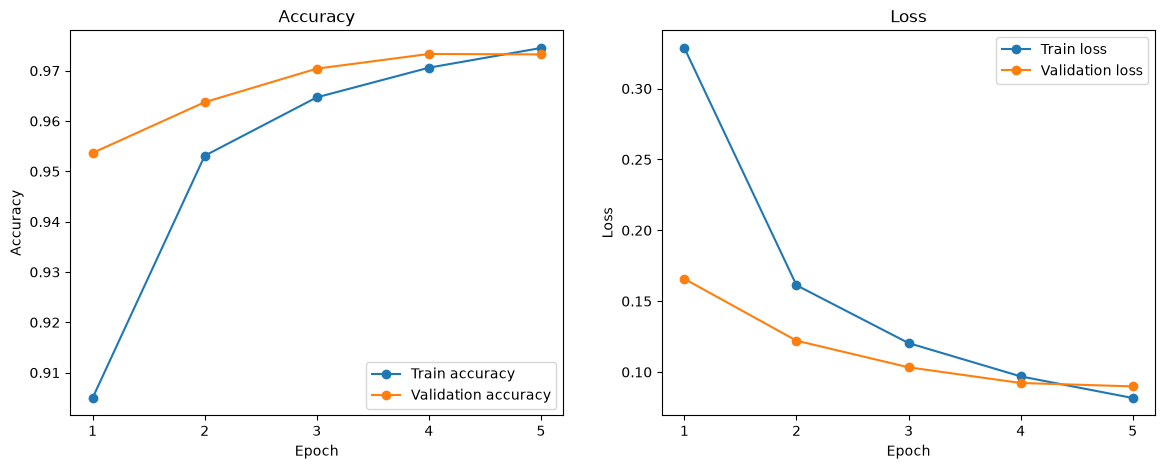

In [10]:
# Biểu đồ accuracy, loss sau mỗi epoch
epochs = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['accuracy'], 'o-', label='Train accuracy')
plt.plot(epochs, history.history['val_accuracy'], 'o-', label='Validation accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xticks(epochs)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['loss'], 'o-', label='Train loss')
plt.plot(epochs, history.history['val_loss'], 'o-', label='Validation loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.show()

Đặng Phan Duy - 6451071010

## Câu i

In [11]:
# Dự đoán xác suất cho mỗi mẫu và mỗi class, chọn class có xác suất lớn nhất
test_prob = model.predict(test_images)
test_pred = np.argmax(test_prob, axis=1)
print("Predict:", test_pred[:20])
print("Actual: ", test_labels[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predict: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Actual:  [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


Đặng Phan Duy - 6451071010

## Câu j

In [12]:
# Accuracy của mô hình trên tập test
nn_score = metrics.accuracy_score(test_labels, test_pred)
print("Accuracy:", nn_score)

Accuracy: 0.9745


Đặng Phan Duy - 6451071010

## Câu k

In [13]:
# Precision, Recall, F1-score của từng lớp và trung bình
print("Report:\n", metrics.classification_report(test_labels, test_pred, digits=4))

Report:
               precision    recall  f1-score   support

           0     0.9877    0.9867    0.9872       980
           1     0.9850    0.9868    0.9859      1135
           2     0.9610    0.9777    0.9693      1032
           3     0.9620    0.9762    0.9690      1010
           4     0.9688    0.9796    0.9742       982
           5     0.9741    0.9709    0.9725       892
           6     0.9761    0.9802    0.9781       958
           7     0.9765    0.9708    0.9737      1028
           8     0.9719    0.9579    0.9648       974
           9     0.9817    0.9564    0.9689      1009

    accuracy                         0.9745     10000
   macro avg     0.9745    0.9743    0.9744     10000
weighted avg     0.9746    0.9745    0.9745     10000



Đặng Phan Duy - 6451071010

## Câu l

In [14]:
nn_cm = metrics.confusion_matrix(test_labels, test_pred)

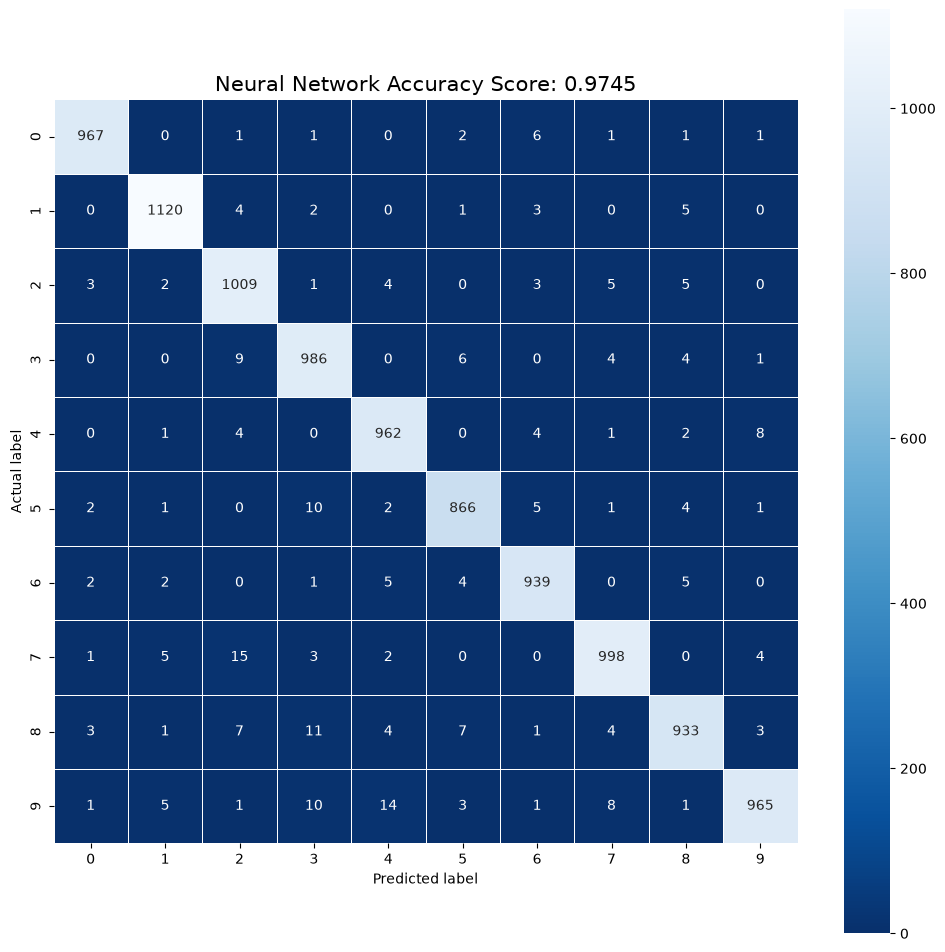

In [15]:
plt.figure(figsize=(12,12))
sns.heatmap(nn_cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Neural Network Accuracy Score: {0}'.format(nn_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu m

Ảnh 0: Predict = 7 - Actual = 7
Ảnh 1: Predict = 2 - Actual = 2
Ảnh 2: Predict = 1 - Actual = 1
Ảnh 3: Predict = 0 - Actual = 0
Ảnh 4: Predict = 4 - Actual = 4


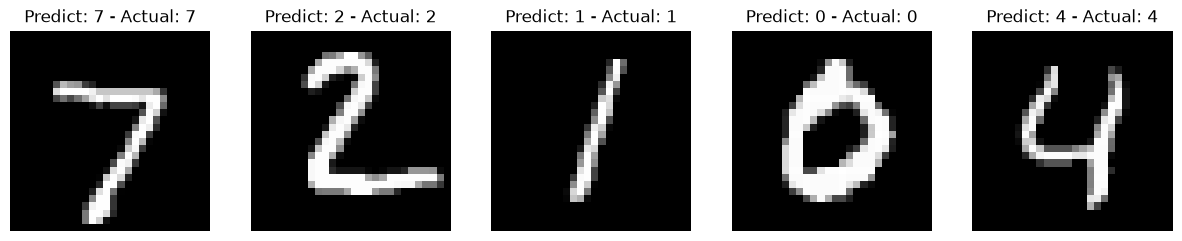

In [16]:
# Kết quả phân lớp của 05 ảnh đầu tiên trong tập test
plt.figure(figsize=(15, 4))
for image_index in range(5):
    img = np.expand_dims(test_images[image_index], axis=0)   # (1, 28, 28)
    pred = np.argmax(model.predict(img, verbose=0), axis=1)[0]
    print("Ảnh {0}: Predict = {1} - Actual = {2}".format(image_index, pred, test_labels[image_index]))

    plt.subplot(1, 5, image_index + 1)
    plt.imshow(test_images[image_index], cmap='gray')
    plt.title('Predict: {0} - Actual: {1}'.format(pred, test_labels[image_index]))
    plt.axis('off')
plt.show()

Đặng Phan Duy - 6451071010

## Câu n

Số ảnh bị phân lớp sai: 255 / 10000
Ảnh 151: Predict = 8 - Actual = 9
Ảnh 247: Predict = 2 - Actual = 4
Ảnh 321: Predict = 7 - Actual = 2
Ảnh 340: Predict = 3 - Actual = 5
Ảnh 359: Predict = 4 - Actual = 9


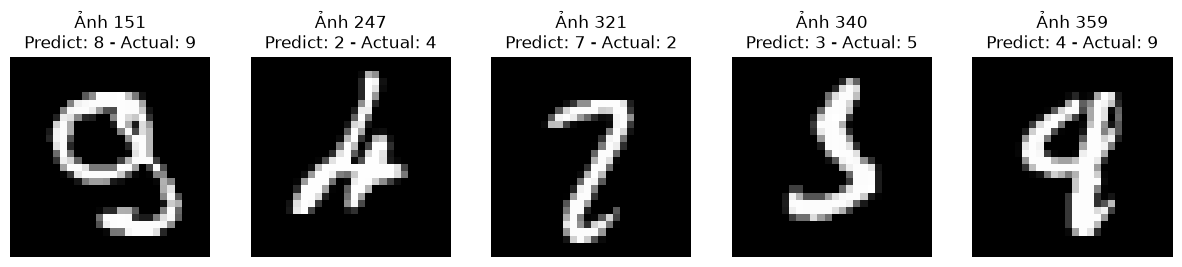

In [17]:
# 05 kết quả đầu tiên phân lớp sai so với nhãn thực tế trong tập test
wrong_index = np.where(test_pred != test_labels)[0]
print("Số ảnh bị phân lớp sai:", len(wrong_index), "/", len(test_labels))

plt.figure(figsize=(15, 4))
for i, image_index in enumerate(wrong_index[:5]):
    print("Ảnh {0}: Predict = {1} - Actual = {2}".format(image_index, test_pred[image_index], test_labels[image_index]))

    plt.subplot(1, 5, i + 1)
    plt.imshow(test_images[image_index], cmap='gray')
    plt.title('Ảnh {0}\nPredict: {1} - Actual: {2}'.format(image_index, test_pred[image_index], test_labels[image_index]))
    plt.axis('off')
plt.show()

Đặng Phan Duy - 6451071010